# Segmentação de pluma de fumaça com SAM 2

**Grupo:** André Ferreira Santos (176013), André Souza de Almeida (176024), Letícia Abrahão Moreira (176559), Lucas Alves Gazale (176565)

**Caso:** incêndio na Refinaria Henrique Lage (Revap), São José dos Campos (SP), 29/09/2019, parte do projeto da disciplina de Modelagem Computacional.


Imagem: `imagem_pluma.png` · Modelo: `facebook/sam2.1-hiera-small`

Quatro configurações de prompt (ponto, caixa, pontos positivos/negativos e caixa + pontos), cada uma mostrando imagem original, máscara binária e sobreposição.

In [32]:
!pip install -q -U transformers accelerate

In [33]:
import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import binary_dilation
from transformers import Sam2Processor, Sam2Model

url_imagem = "https://raw.githubusercontent.com/AndreFerreira20/Modelagem-Computacional/main/exc_19_10/imagem_pluma.png"
caminho_imagem = "/content/imagem_pluma.png"

!wget -q {url_imagem} -O {caminho_imagem}
print("Tamanho do arquivo:", os.path.getsize(caminho_imagem), "bytes")

imagem = Image.open(caminho_imagem).convert("RGB")

device = "cuda" if torch.cuda.is_available() else "cpu"
model_id = "facebook/sam2.1-hiera-small"

processor = Sam2Processor.from_pretrained(model_id)
model = Sam2Model.from_pretrained(model_id).to(device)
model.eval()

print("Rodando em:", device)
print("Tamanho:", imagem.size)

Tamanho do arquivo: 1479149 bytes


[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/357 [00:00<?, ?it/s]

Rodando em: cpu
Tamanho: (1227, 922)


Imagem com grade para escolher as coordenadas dos prompts.

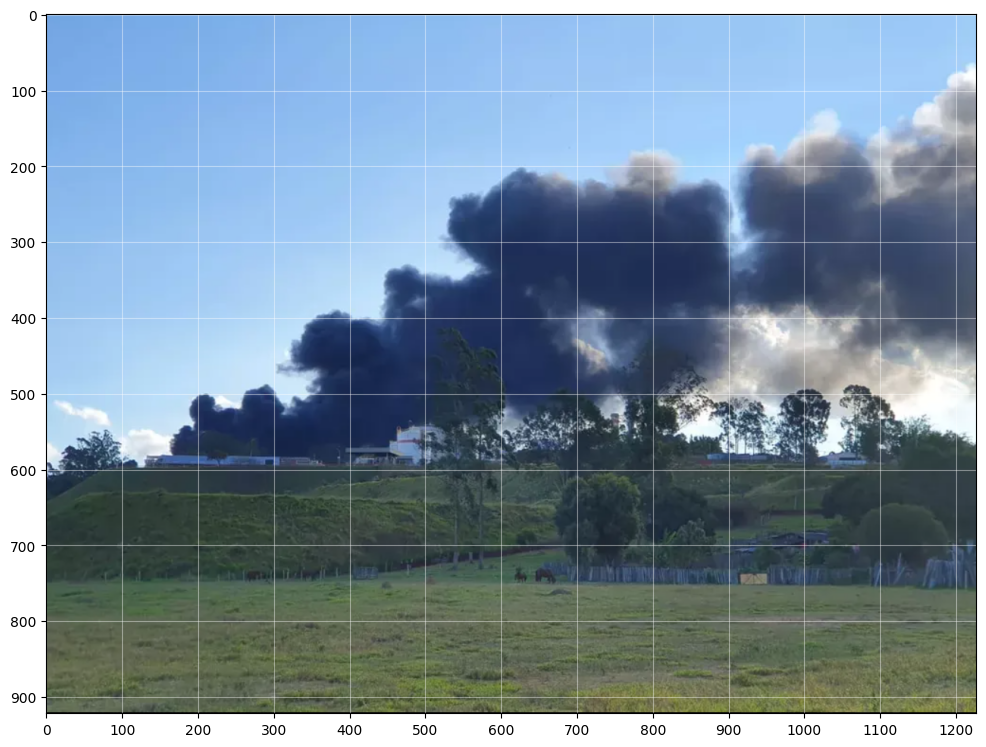

In [34]:
def mostrar_grade(imagem, passo=100):
    plt.figure(figsize=(12, 12))
    plt.imshow(imagem)
    plt.xticks(np.arange(0, imagem.size[0], passo))
    plt.yticks(np.arange(0, imagem.size[1], passo))
    plt.grid(color="white", alpha=0.4)
    plt.show()

mostrar_grade(imagem)

## Funções

In [35]:
def segmentar(imagem, pontos=None, rotulos=None, caixa=None):
    argumentos = {"images": imagem, "return_tensors": "pt"}
    if pontos is not None:
        argumentos["input_points"] = [[pontos]]
        argumentos["input_labels"] = [[rotulos]]
    if caixa is not None:
        argumentos["input_boxes"] = [[caixa]]

    entradas = processor(**argumentos).to(device)

    with torch.no_grad():
        saidas = model(**entradas, multimask_output=False)

    mascaras = processor.post_process_masks(
        saidas.pred_masks.cpu(),
        entradas["original_sizes"]
    )
    return mascaras[0][0][0].numpy() > 0


def desenhar_prompts(ax, pontos, rotulos, caixa):
    i = 0
    while pontos is not None and i < len(pontos):
        cor = "lime" if rotulos[i] == 1 else "red"
        ax.scatter(pontos[i][0], pontos[i][1], c=cor, marker="*", s=250, edgecolors="white")
        i += 1
    if caixa is not None:
        ax.add_patch(plt.Rectangle((caixa[0], caixa[1]), caixa[2] - caixa[0], caixa[3] - caixa[1],
                                   fill=False, edgecolor="yellow", linewidth=3))


def mostrar_resultado(imagem, mascara, titulo, pontos=None, rotulos=None, caixa=None):
    sobreposta = np.array(imagem).astype(float)
    sobreposta[mascara] = 0.5 * sobreposta[mascara] + 0.5 * np.array([255, 0, 0])

    fig, eixos = plt.subplots(1, 3, figsize=(18, 6))
    eixos[0].imshow(imagem)
    desenhar_prompts(eixos[0], pontos, rotulos, caixa)
    eixos[0].set_title("Original + prompts")
    eixos[1].imshow(mascara, cmap="gray")
    eixos[1].set_title("Máscara binária")
    eixos[2].imshow(sobreposta.astype(np.uint8))
    eixos[2].set_title("Máscara sobreposta")

    i = 0
    while i < 3:
        eixos[i].axis("off")
        i += 1
    fig.suptitle(titulo, fontsize=14)
    plt.show()


def medir(imagem, mascara, anel_px=40):
    cinza = np.array(imagem.convert("L")).astype(float)
    saturacao = np.array(imagem.convert("HSV"))[:, :, 1].astype(float)
    anel = binary_dilation(mascara, iterations=anel_px) & ~mascara

    return {
        "area_px": int(mascara.sum()),
        "area_%": round(100 * mascara.mean(), 2),
        "brilho_dentro": round(cinza[mascara].mean(), 1),
        "brilho_anel": round(cinza[anel].mean(), 1),
        "contraste": round(abs(cinza[mascara].mean() - cinza[anel].mean()), 1),
        "saturacao_dentro": round(saturacao[mascara].mean(), 1),
        "saturacao_anel": round(saturacao[anel].mean(), 1),
    }


def iou(a, b):
    return round((a & b).sum() / (a | b).sum(), 3)

## Configurações de prompt
Ajuste as coordenadas com a grade acima. Pontos positivos (`1`) ficam sobre a fumaça e negativos (`0`) sobre céu, nuvem ou prédio que a máscara não deve pegar.

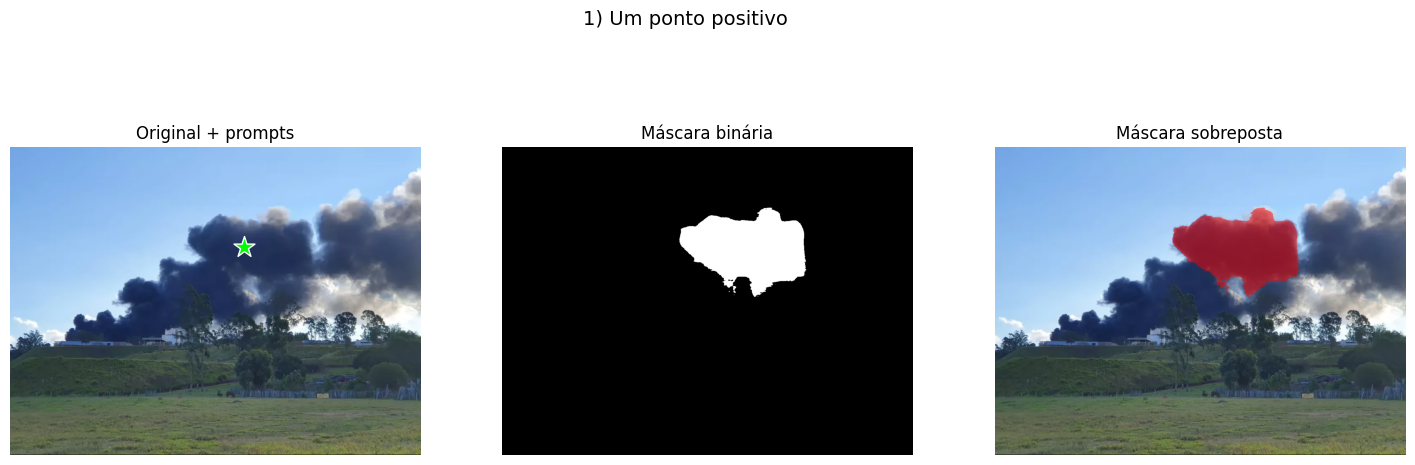

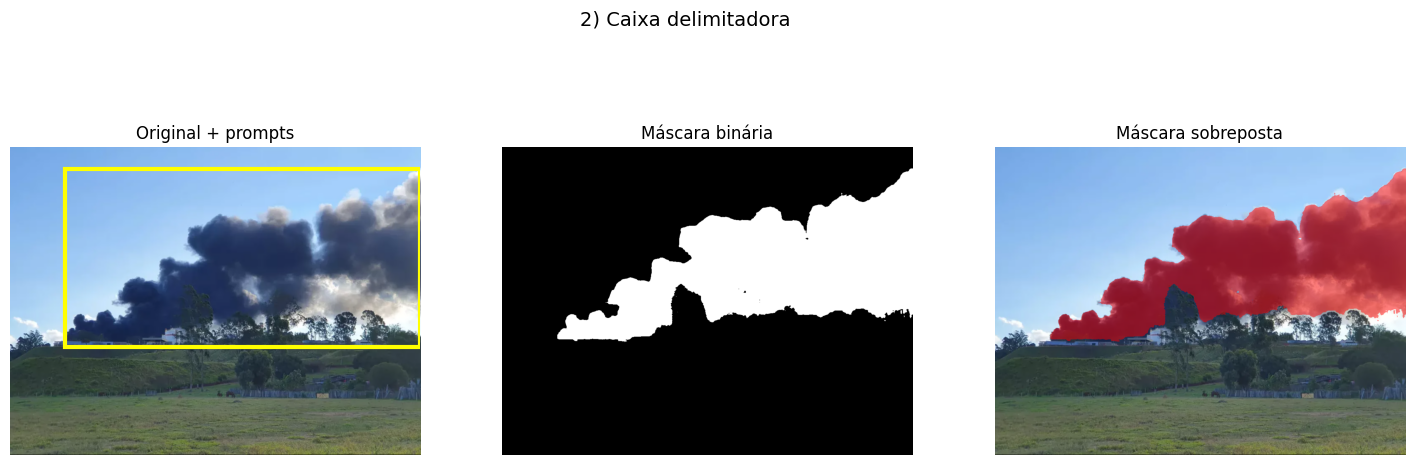

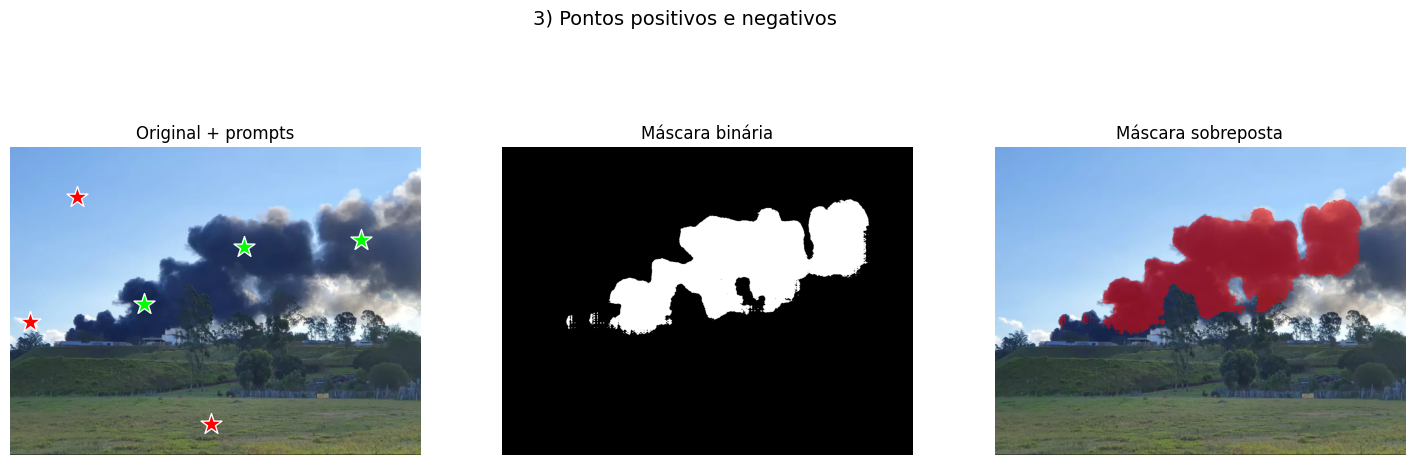

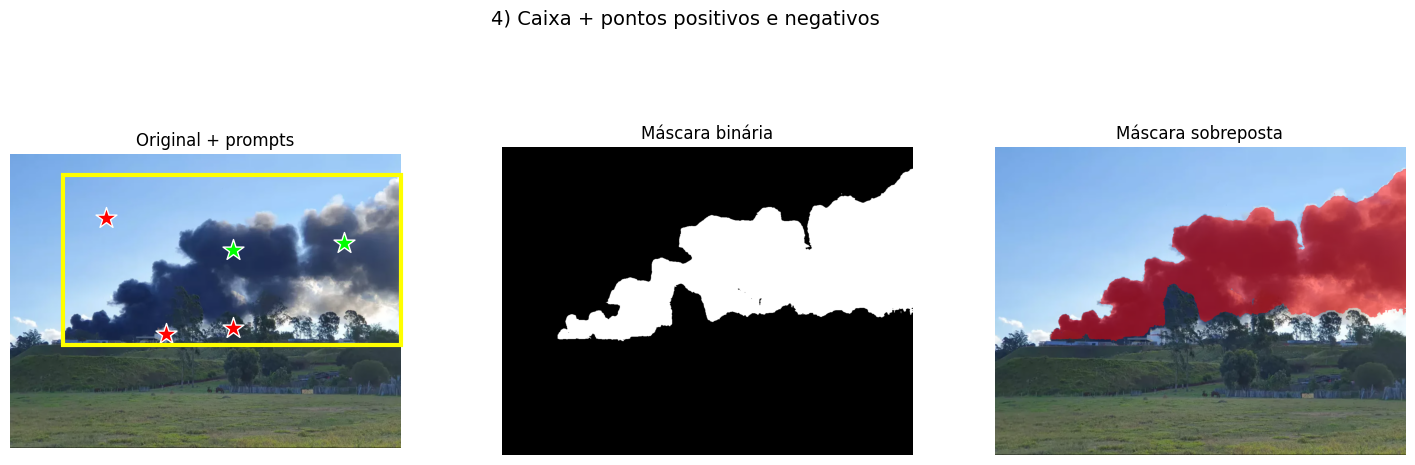

In [36]:
configuracoes = [
    {
        "nome": "1) Um ponto positivo",
        "pontos": [[700, 300]],
        "rotulos": [1],
        "caixa": None,
    },
    {
        "nome": "2) Caixa delimitadora",
        "pontos": None,
        "rotulos": None,
        "caixa": [165, 65, 1227, 600],
    },
    {
        "nome": "3) Pontos positivos e negativos",
        "pontos": [[700, 300], [400, 470], [1050, 280], [200, 150], [60, 525], [600, 830]],
        "rotulos": [1, 1, 1, 0, 0, 0],
        "caixa": None,
    },
    {
        "nome": "4) Caixa + pontos positivos e negativos",
        "pontos": [[700, 300], [1050, 280], [300, 200], [490, 565], [700, 545]],
        "rotulos": [1, 1, 0, 0, 0],
        "caixa": [165, 65, 1227, 600],
    },
]

mascaras = {}
i = 0
while i < len(configuracoes):
    cfg = configuracoes[i]
    mascara = segmentar(imagem, cfg["pontos"], cfg["rotulos"], cfg["caixa"])
    mascaras[cfg["nome"]] = mascara
    mostrar_resultado(imagem, mascara, cfg["nome"], cfg["pontos"], cfg["rotulos"], cfg["caixa"])
    i += 1

## Comparação entre as configurações

In [37]:
nomes = list(mascaras.keys())
referencia = mascaras[nomes[-1]]

linhas = []
i = 0
while i < len(nomes):
    linha = medir(imagem, mascaras[nomes[i]])
    linha["IoU vs config 4"] = iou(mascaras[nomes[i]], referencia)
    linhas.append(linha)
    i += 1

tabela = pd.DataFrame(linhas, index=nomes)
tabela

,area_px,area_%,brilho_dentro,brilho_anel,contraste,saturacao_dentro,saturacao_anel,IoU vs config 4
1) Um ponto positivo,63505,5.61,70.1,141.8,71.7,136.3,97.3,0.249
2) Caixa delimitadora,259103,22.90,93.6,157.2,63.6,105.7,75.1,0.982
3) Pontos positivos e negativos,155319,13.73,69.8,142.3,72.5,133.9,84.4,0.609
4) Caixa + pontos positivos e negativos,254582,22.50,92.6,157.5,64.9,106.2,75.5,1.000


## Avaliação

**A máscara cobre a pluma?**
Depende muito do prompt. Com um ponto positivo (config 1), a máscara cobriu só o lóbulo central, 5,61% da imagem (63.505 px), e deixou de fora a base à esquerda e a nuvem escura à direita. Com a caixa (config 2), a máscara passou a cobrir a pluma inteira, de ponta a ponta, com 22,90% da imagem (259.103 px). Com pontos positivos e negativos (config 3), ficou num meio-termo, 13,73% (155.319 px), pegando os lóbulos central e direito mas não a pluma toda.

**Inclui regiões que não pertencem a ela?**
Em nenhuma configuração a máscara vazou para o céu azul, o pasto ou o prédio. Nas configs 2 e 4, a máscara inclui a parte clara e acinzentada da fumaça no lado direito, perto das nuvens brancas, e não dá para ter certeza se essa região é fumaça ou nuvem. Também há um recorte na máscara onde a árvore passa na frente da pluma, o que é correto, e uma borda inferior reta no lado direito, onde a máscara termina junto da linha das árvores.

**Deixa partes da fumaça de fora?**
Sim, nas configs 1 e 3. A config 1 deixou de fora quase tudo menos o lóbulo central. A config 3 pegou o núcleo e a base central, mas perdeu a ponta esquerda da base (sobraram só alguns fragmentos soltos), o topo da nuvem à direita e parte da região clara. As configs 2 e 4 cobriram praticamente toda a fumaça visível.

**Comparação numérica entre as configurações**
O IoU em relação à config 4 foi 0,249 (config 1), 0,982 (config 2) e 0,609 (config 3). Ou seja, as configs 2 e 4 são quase a mesma máscara, e os pontos negativos que adicionei dentro da caixa mudaram só cerca de 4.500 px (259.103 contra 254.582). Como a caixa já delimitava bem a região, os pontos negativos tiveram pouco a corrigir. Esse IoU é relativo à config 4, e não a uma máscara de referência feita à mão.

**O que dificultou a segmentação?**
- *Iluminação:* a fumaça está em contraluz. O núcleo é muito escuro (brilho médio de cerca de 70 nas configs 1 e 3), mas a parte à direita recebe luz e fica cinza-clara. Quando a máscara inclui essa parte (configs 2 e 4), o brilho médio dentro da máscara sobe para cerca de 93.
- *Contraste:* contra o céu azul o contraste é alto (diferença de brilho com o anel ao redor de cerca de 72 nas configs 1 e 3), e a borda saiu bem definida. Nas configs 2 e 4 o contraste caiu para cerca de 64, porque a máscara passa a englobar a fumaça clara, cujo brilho é mais próximo do entorno (brilho do anel de 157, contra 142 nas configs 1 e 3).
- *Semelhança com nuvens:* a saturação dentro da máscara cai de cerca de 134–136 (configs 1 e 3, só o núcleo escuro) para cerca de 106 (configs 2 e 4). Isso indica que a parte clara da fumaça é pouco saturada, como as nuvens brancas ao lado, e o modelo não tem uma pista de cor para separar uma da outra.
- *Obstáculos na frente:* árvores e o prédio cortam a base da pluma e geram recortes e bordas irregulares na máscara.

**O que melhorou com os prompts?**
Um ponto só (config 1) é insuficiente para uma pluma com vários lóbulos: o SAM segmenta só o objeto em volta do ponto. A caixa (config 2) foi o maior ganho, porque indica a extensão da pluma e passou de 5,61% para 22,90% da imagem. Os pontos positivos e negativos sem caixa (config 3) deram mais controle sobre o que entra, mas, sem a caixa, a máscara perdeu partes da fumaça. Caixa mais pontos (config 4) ficou praticamente igual à caixa sozinha (IoU 0,982), então o ganho dos pontos negativos foi pequeno nesta imagem. Considerei a config 4 a melhor porque cobre a pluma inteira e ainda dá o controle extra dos pontos negativos, mas o resultado depende de decidir se a região clara à direita é fumaça.

## Máscara final

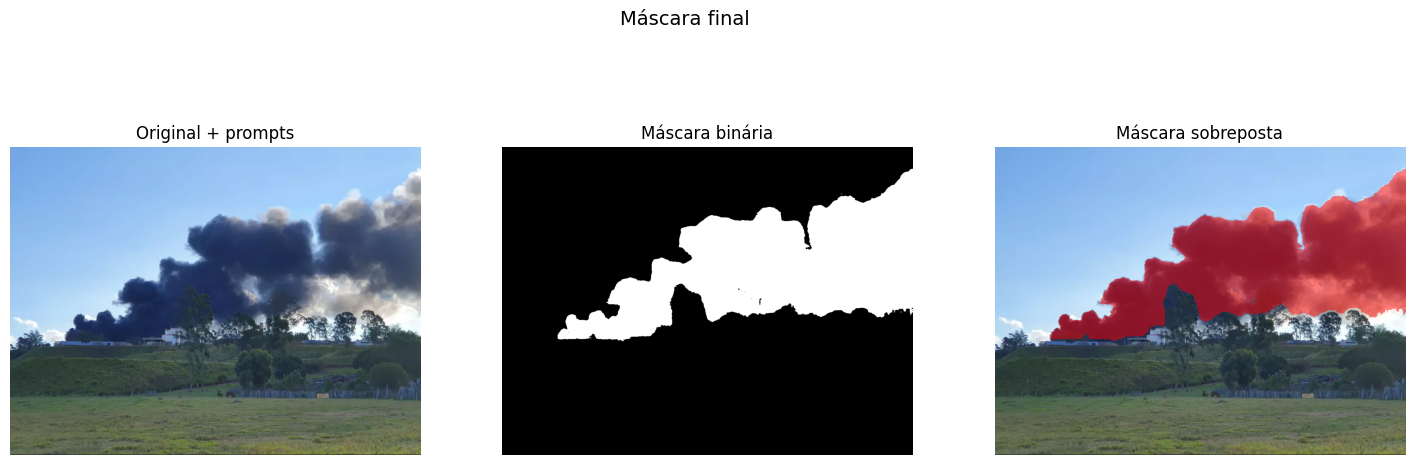

In [38]:
mascara_final = mascaras[nomes[-1]]
Image.fromarray((mascara_final * 255).astype(np.uint8)).save("mascara_final_pluma.png")
mostrar_resultado(imagem, mascara_final, "Máscara final")